# AgriFlyTwin: Moringa Leaf Classification
## Using a Decision Tree

**Author:** Amirah Al-baqami

### Project Overview
This project explores classifying close-up Moringa leaf images
using colour and texture features and a Decision Tree classifier.
It is inspired by the plant-monitoring goals of AgriFlyTwin.

### Dataset
MoringaLeafNet, Version 5 — 2,817 original images in four categories:
- Bacterial Leaf Spot
- Cercospora Leaf Spot
- Healthy
- Yellow

### Data Attribution
Khan, A., Preanto, S. A., Paul, T., and Bijoy, M. H. I. (2025).
MoringaLeafNet: A Multi-Class Leaf Disease Dataset for Precision
Agriculture and Deep Learning Research. Mendeley Data, V5.

Source: https://data.mendeley.com/datasets/w8sr775pjb/5
DOI: 10.17632/w8sr775pjb.5
License: CC BY 4.0

The dataset was created by its original contributors.
This project uses the original images and resizes them for feature extraction.

### Running this notebook
Attach the MoringaLeafNet V5 original images as Kaggle input, then run cells from top to bottom. The input must contain a folder named `Original Image` with the four category subfolders.
Saved outputs below are retained from the original run; this edited notebook was not re-executed. Exact image hashing and feature extraction may take several minutes.


## 1. Locate and inspect the dataset


In [7]:
from pathlib import Path

data_path = Path("/kaggle/input")

original_path = next(data_path.rglob("Original Image"))
image_extensions = {".jpg", ".jpeg", ".png"}

total = 0

for folder in sorted(original_path.iterdir()):
    if folder.is_dir():
        count = sum(
            1 for p in folder.rglob("*")
            if p.is_file() and p.suffix.lower() in image_extensions
        )
        total += count
        print(f"{folder.name}: {count}")

print("Total images:", total)

Bacterial Leaf Spot: 857
Cercospora Leaf Spot: 568
Healthy: 597
Yellow: 795
Total images: 2817


## 2. Preview the four categories


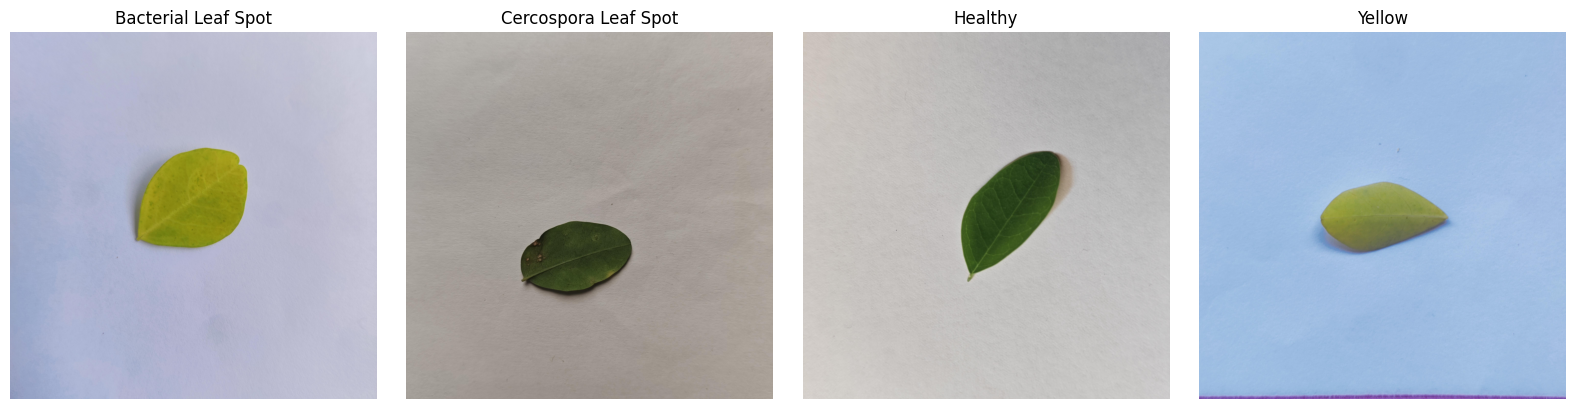

In [8]:
import matplotlib.pyplot as plt
from PIL import Image

folders = sorted(
    folder for folder in original_path.iterdir()
    if folder.is_dir()
)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, folder in zip(axes, folders):
    image_path = next(
        p for p in sorted(folder.rglob("*"))
        if p.is_file() and p.suffix.lower() in image_extensions
    )

    with Image.open(image_path) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(folder.name)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 3. Check exact duplicate images


In [10]:
import hashlib
import pandas as pd
from PIL import Image, ImageOps

records = []

for folder in folders:
    for path in sorted(folder.rglob("*")):
        if path.is_file() and path.suffix.lower() in image_extensions:
            with Image.open(path) as img:
                img = ImageOps.exif_transpose(img).convert("RGB")
                image_hash = hashlib.sha256(
                    str(img.size).encode() + img.tobytes()
                ).hexdigest()

            records.append({
                "path": str(path),
                "label": folder.name,
                "image_hash": image_hash
            })

images_df = pd.DataFrame(records)

print("Total images:", len(images_df))
print("Exact duplicates:",
      images_df.duplicated("image_hash").sum())
print("Conflicting labels:",
      (images_df.groupby("image_hash")["label"].nunique() > 1).sum())

Total images: 2817
Exact duplicates: 0
Conflicting labels: 0


## 4. Split training and testing data


In [11]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    images_df,
    test_size=0.20,
    random_state=42,
    stratify=images_df["label"]
)

print("Training images:", len(train_df))
print("Testing images:", len(test_df))

print("\nImages per class:")
print(
    pd.DataFrame({
        "Training": train_df["label"].value_counts(),
        "Testing": test_df["label"].value_counts()
    })
)

Training images: 2253
Testing images: 564

Images per class:
                      Training  Testing
label                                  
Bacterial Leaf Spot        685      172
Yellow                     636      159
Healthy                    478      119
Cercospora Leaf Spot       454      114


## 5. Extract colour and texture features


In [12]:
import cv2
import numpy as np

feature_names = [
    "Hue mean", "Saturation mean", "Brightness mean",
    "Hue variation", "Saturation variation", "Brightness variation",
    "Texture variation"
]

def extract_features(path):
    # Read a smaller version to reduce processing time
    image = cv2.imread(str(path), cv2.IMREAD_REDUCED_COLOR_4)

    if image is None:
        raise ValueError(f"Cannot read image: {path}")

    image = cv2.resize(image, (128, 128))
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    means = hsv.mean(axis=(0, 1))
    variations = hsv.std(axis=(0, 1))
    texture = cv2.Laplacian(gray, cv2.CV_64F).var()

    return np.concatenate([means, variations, [texture]])

def prepare_features(frame, name):
    features = []

    for number, path in enumerate(frame["path"], start=1):
        features.append(extract_features(path))

        if number % 100 == 0 or number == len(frame):
            print(f"{name}: {number}/{len(frame)}", flush=True)

    return np.asarray(features)

X_train = prepare_features(train_df, "Training")
X_test = prepare_features(test_df, "Testing")

y_train = train_df["label"].to_numpy()
y_test = test_df["label"].to_numpy()

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training: 100/2253
Training: 200/2253
Training: 300/2253
Training: 400/2253
Training: 500/2253
Training: 600/2253
Training: 700/2253
Training: 800/2253
Training: 900/2253
Training: 1000/2253
Training: 1100/2253
Training: 1200/2253
Training: 1300/2253
Training: 1400/2253
Training: 1500/2253
Training: 1600/2253
Training: 1700/2253
Training: 1800/2253
Training: 1900/2253
Training: 2000/2253
Training: 2100/2253
Training: 2200/2253
Training: 2253/2253
Testing: 100/564
Testing: 200/564
Testing: 300/564
Testing: 400/564
Testing: 500/564
Testing: 564/564
Training features: (2253, 7)
Testing features: (564, 7)


## 6. Train the Decision Tree


In [13]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=10,
    random_state=42
)

model.fit(X_train, y_train)

print("Training complete!")
print("Tree depth:", model.get_depth())
print("Number of leaves:", model.get_n_leaves())

Training complete!
Tree depth: 5
Number of leaves: 31


## 7. Evaluate predictions


In [15]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = model.predict(X_test)

train_accuracy = accuracy_score(
    y_train, model.predict(X_train)
)
test_accuracy = accuracy_score(y_test, y_pred)

print(f"Training accuracy: {train_accuracy:.2%}")
print(f"Testing accuracy: {test_accuracy:.2%}")

print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

Training accuracy: 73.55%
Testing accuracy: 70.92%

Classification report:
                      precision    recall  f1-score   support

 Bacterial Leaf Spot       0.68      0.69      0.69       172
Cercospora Leaf Spot       0.62      0.79      0.69       114
             Healthy       0.72      0.63      0.67       119
              Yellow       0.82      0.73      0.77       159

            accuracy                           0.71       564
           macro avg       0.71      0.71      0.71       564
        weighted avg       0.72      0.71      0.71       564



## 8. Inspect the confusion matrix


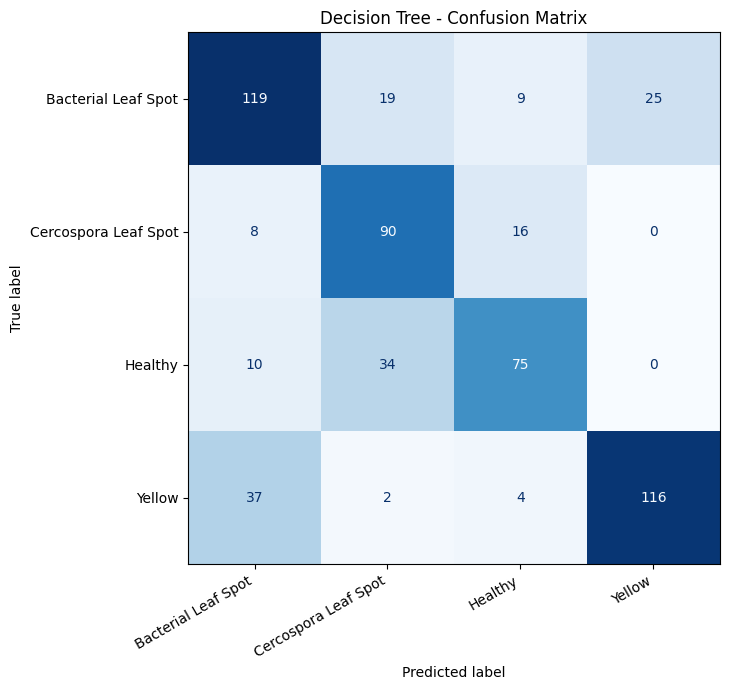

In [16]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(9, 7))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=model.classes_,
    display_labels=model.classes_,
    cmap="Blues",
    ax=ax,
    colorbar=False
)

ax.set_title("Decision Tree - Confusion Matrix")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 9. Visualize the tree


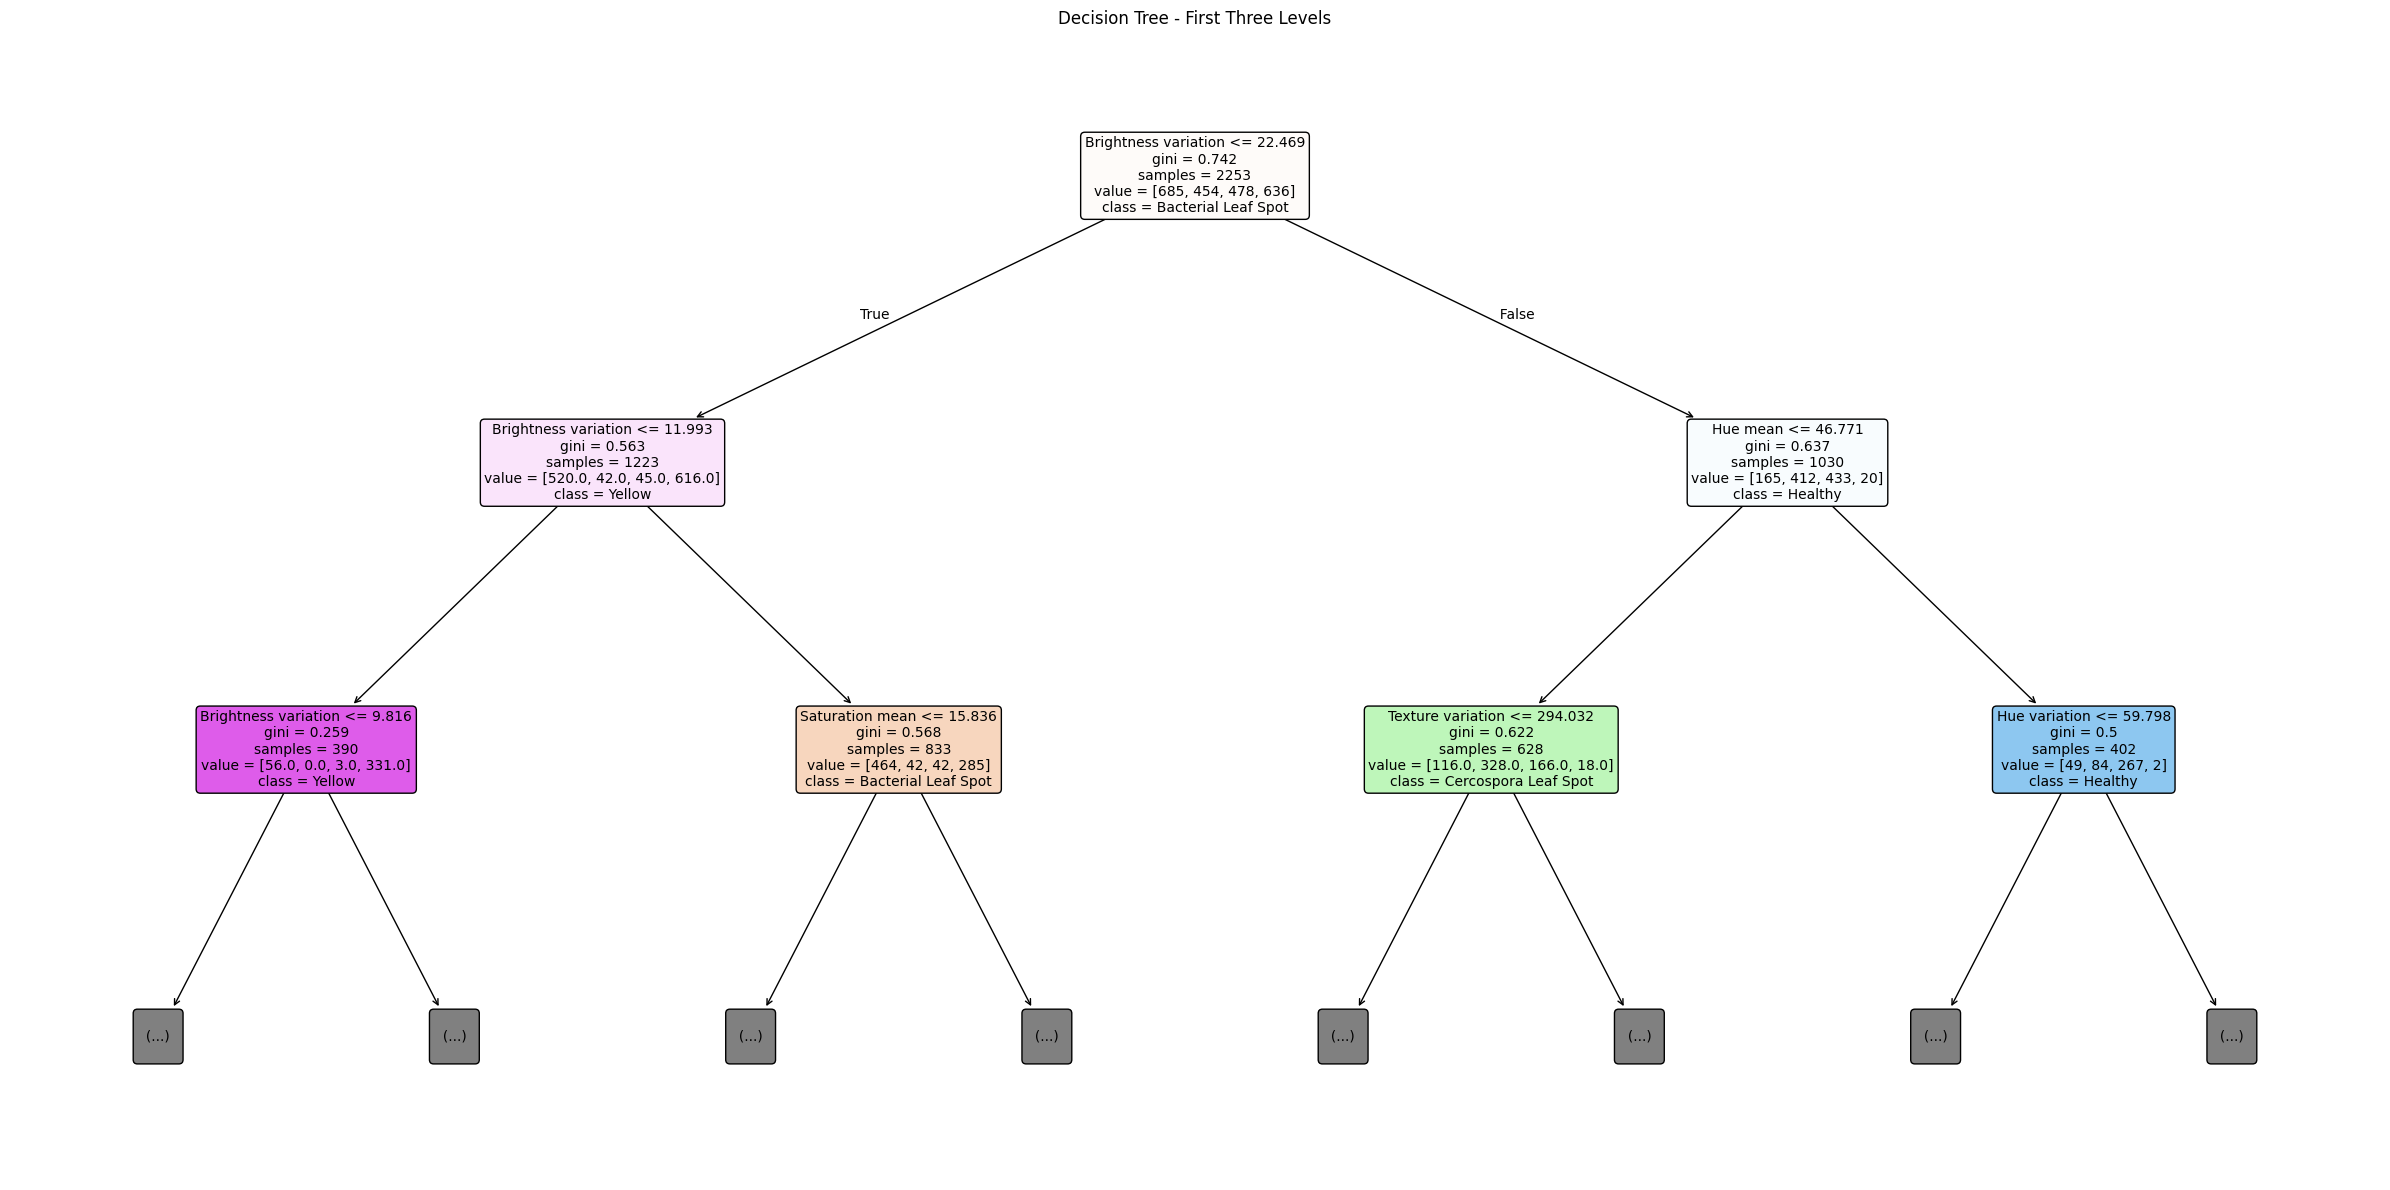

In [17]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(24, 12))

plot_tree(
    model,
    feature_names=feature_names,
    class_names=model.classes_,
    filled=True,
    rounded=True,
    max_depth=2,
    fontsize=10
)

plt.title("Decision Tree - First Three Levels")
plt.tight_layout()
plt.show()

## 10. Inspect example predictions


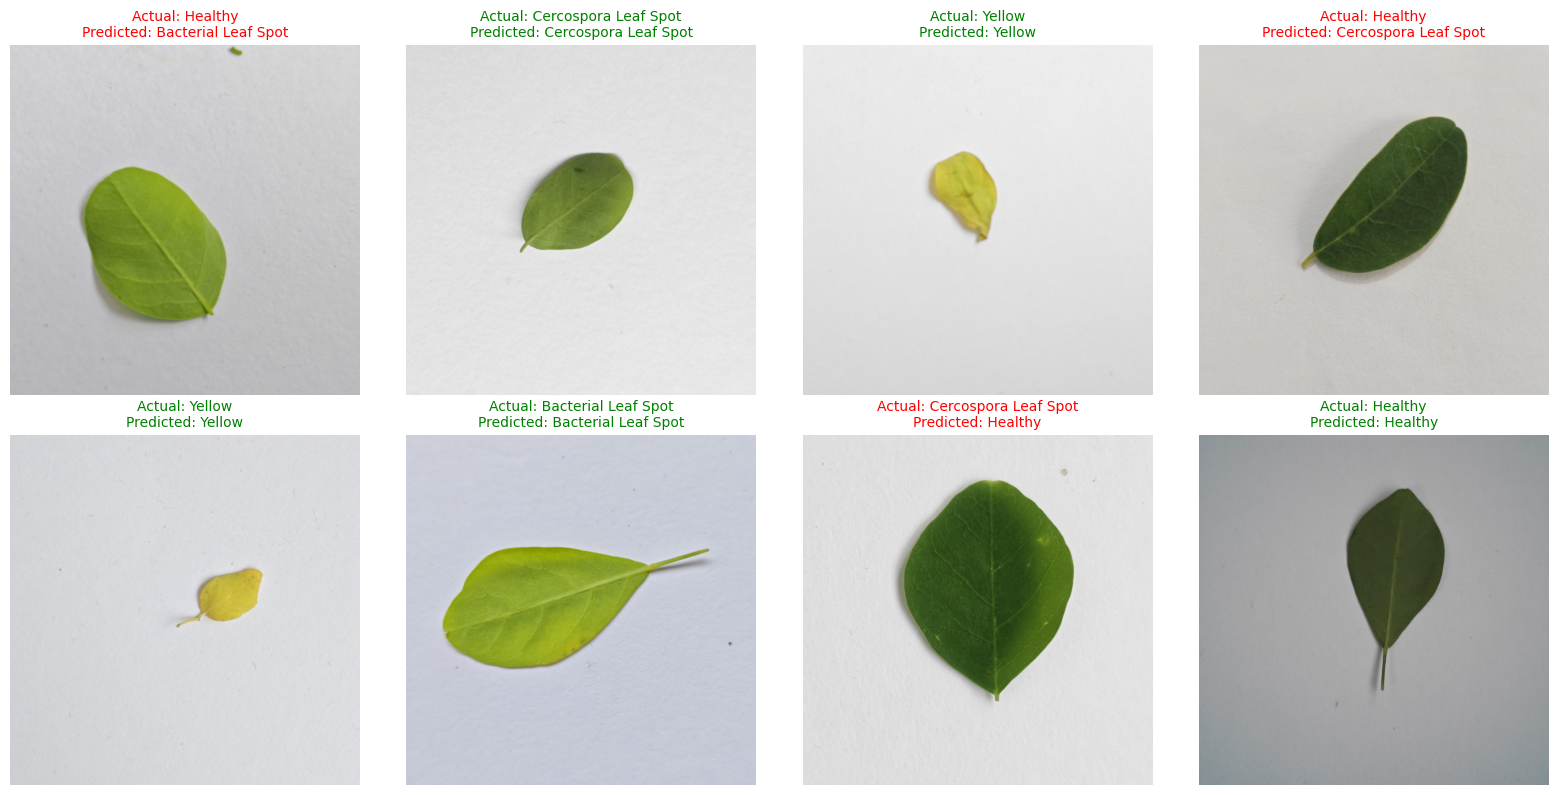

In [18]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

sample_indices = np.random.default_rng(42).choice(
    len(test_df), size=8, replace=False
)

for ax, index in zip(axes.flat, sample_indices):
    row = test_df.iloc[index]
    actual = y_test[index]
    predicted = y_pred[index]

    with Image.open(row["path"]) as img:
        ax.imshow(ImageOps.exif_transpose(img).convert("RGB"))

    color = "green" if actual == predicted else "red"

    ax.set_title(
        f"Actual: {actual}\nPredicted: {predicted}",
        color=color,
        fontsize=10
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

### Results and Interpretation

The Decision Tree classified Moringa leaf images into four categories:
Bacterial Leaf Spot, Cercospora Leaf Spot, Healthy, and Yellow.

Seven colour and texture features were extracted from each image.
The dataset was divided into 2,253 training images and 564 testing
images, preserving the class proportions.

Training accuracy was 73.55%, while testing accuracy was 70.92%.
The small difference suggests limited overfitting in this split.
The Yellow category achieved the highest F1-score of 0.77.

### Tree Complexity and Generalization

The tree had a maximum depth of 5 and 31 leaves.
A very shallow tree may miss useful patterns, while a very deep tree
may memorize training examples and perform poorly on new images.
We limited the depth and required at least 10 samples per leaf
to reduce model complexity.

### Limitations

The model uses simple features from the whole image, so background
and lighting may influence its predictions. Its performance on new
farms or drone images has not been established. Yellowing is a visible
symptom and does not identify a specific cause.